# Análisis Exploratorio

### 0. Librerias

In [106]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### 1. Carga de Datos

In [126]:
ruta = "../data/raw/online_retail_II.xlsx"

df_2009_2010 = pd.read_excel(ruta,  sheet_name="Year 2009-2010")
df_2010_2011 = pd.read_excel(ruta, sheet_name="Year 2010-2011")

df_2009_2010.shape, df_2010_2011.shape

((525461, 8), (541910, 8))

In [ ]:
df = pd.concat([df_2009_2010, df_2010_2011], ignore_index=True)
df.shape

(1067371, 8)

### 2. Exploración y calidad de los datos
En esta sección analizaremos los valores ausentes, duplicados y posibles inconsistencias del dataset antes de realizar la limpieza.

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.1+ MB


In [ ]:
df.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom


In [ ]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Invoice,1067371.0,53628.0,537434.0,1350.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,1067371,5305,85123A,5829,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,1062989,5698,WHITE HANGING HEART T-LIGHT HOLDER,5918,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1067371.0,NaN,NaN,NaN,9.938898,-80995.0,1.0,3.0,10.0,80995.0,172.705794
InvoiceDate,1067371,NaN,NaN,NaN,2011-01-02 21:13:55.394029,2009-12-01 07:45:00,2010-07-09 09:46:00,2010-12-07 15:28:00,2011-07-22 10:23:00,2011-12-09 12:50:00,NaN
Price,1067371.0,NaN,NaN,NaN,4.649388,-53594.36,1.25,2.1,4.15,38970.0,123.553059
Customer ID,824364.0,NaN,NaN,NaN,15324.638504,12346.0,13975.0,15255.0,16797.0,18287.0,1697.46445
Country,1067371,43,United Kingdom,981330,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [44]:
df.isna().sum().sort_values(ascending=False)

Customer ID    243007
Description      4382
StockCode           0
Invoice             0
Quantity            0
InvoiceDate         0
Price               0
Country             0
dtype: int64

El dataset contiene 1.067.371 transacciones, 53.628 facturas y 5.305 productos entre 2009 y 2011.
Existen valores ausentes en `Customer ID` y `Description`, además de 34.335 duplicados exactos.
Se observan valores negativos en `Quantity` y `Price`, asociados potencialmente a cancelaciones o ajustes.
Antes de modelar, será necesario analizar y definir el tratamiento de estos casos.

In [45]:
df.dtypes

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

In [46]:
# Cancelaciones
df["Invoice"].astype(str).str.startswith("C").value_counts()

Invoice
False    1047877
True       19494
Name: count, dtype: int64

In [47]:
# Cantidades negativas
(df["Quantity"] < 0).sum()

np.int64(22950)

In [48]:
# Precios negativos
(df["Price"] < 0).sum()

np.int64(5)

In [49]:
# Precio = 0
(df["Price"] == 0).sum()

np.int64(6202)

In [50]:
df['Customer ID'].nunique()

5942

In [51]:
# Clientes nulos por tipo de transacción
df.groupby(
    df["Invoice"].astype(str).str.startswith("C")
)["Customer ID"].agg(["count", "size"])

,count,size
Invoice,,
False,805620,1047877
True,18744,19494


Las cancelaciones representan 19.494 transacciones frente a 1.047.877 transacciones no canceladas.
Existen 242.257 ventas y 750 cancelaciones sin Customer ID, por lo que no todas las transacciones pueden asociarse a un cliente.

In [52]:
# Distribución de países
df["Country"].value_counts().head(5)

Country
United Kingdom    981330
EIRE               17866
Germany            17624
France             14330
Netherlands         5140
Name: count, dtype: int64

Se identifican 19.494 cancelaciones, 22.950 cantidades negativas y 6.202 registros con precio igual a 0.
Existen 5 valores de precio negativos y 242.257 transacciones sin Customer ID, principalmente en ventas no canceladas. Reino Unido concentra la mayoría de las transacciones. El dataset contiene 5.942 clientes identificados, que serán la unidad principal de análisis para churn y segmentación. 

#### Análisis de valores ausentes
En esta sección analizaremos los valores ausentes para determinar su impacto y decidir qué variables y registros podremos utilizar en el análisis de clientes.

In [53]:
missing = df.isna().sum()
missing_pct = (df.isna().mean() * 100).round(2)

pd.DataFrame({
    "missing": missing,
    "missing_pct": missing_pct
}).sort_values("missing", ascending=False)

,missing,missing_pct
Customer ID,243007,22.77
Description,4382,0.41
StockCode,0,0.00
Invoice,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00


In [54]:
df[df["Customer ID"].isna()].head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
577,489525,85226C,BLUE PULL BACK RACING CAR,1,2009-12-01 11:49:00,0.55,NaN,United Kingdom


`Customer ID` presenta un 22,77% de valores nulos, mientras que `Description` solo un 0,41%.
El resto de variables no contiene valores ausentes.
La ausencia de `Customer ID` será relevante porque limita el análisis a nivel cliente.


#### Análisis de cancelaciones
En esta sección analizaremos las facturas canceladas y su relación con las cantidades negativas para definir posteriormente su tratamiento.

In [55]:
cancelaciones = df[
    df["Invoice"].astype(str).str.startswith("C")
]

cancelaciones[["Quantity", "Price"]].describe()

,Quantity,Price
count,19494.000000,19494.000000
mean,-25.186827,44.872221
std,805.104908,596.335291
min,-80995.000000,0.010000
25%,-6.000000,1.450000
50%,-2.000000,2.950000
75%,-1.000000,6.750000
max,1.000000,38970.000000


In [62]:
cancelaciones["Quantity"].value_counts().sort_values(ascending=False).head(20)

Quantity
-1     8685
-2     2804
-3     1311
-12    1140
-4     1038
-6     1000
-24     485
-5      382
-8      328
-10     283
-48     164
-7      157
-36     117
-9      108
-16     102
-11      83
-20      79
-25      68
-18      62
-72      62
Name: count, dtype: int64

Se identifican 19.494 cancelaciones, todas con cantidades negativas y precios positivos.
La cantidad más frecuente es -1, aunque existen valores extremos como -5.184.
Las cancelaciones deberán excluirse del cálculo de ventas y tratarse separadamente en la construcción de variables de cliente.


#### Análisis temporal
En esta sección analizaremos la distribución temporal de las transacciones para conocer la evolución de la actividad comercial y preparar posteriormente el análisis de comportamiento del cliente.

In [63]:
df["InvoiceDate"].dt.year.value_counts().sort_index()

InvoiceDate
2009     45228
2010    522714
2011    499429
Name: count, dtype: int64

In [64]:
# ¿Cuántas transacciones hay en cada mes del año, independientemente del año?
df["InvoiceDate"].dt.month.value_counts().sort_index()

InvoiceDate
1      66702
2      57095
3      78259
4      63973
5      72353
6      76857
7      72901
8      68590
9      92317
10    119840
11    162726
12    135758
Name: count, dtype: int64

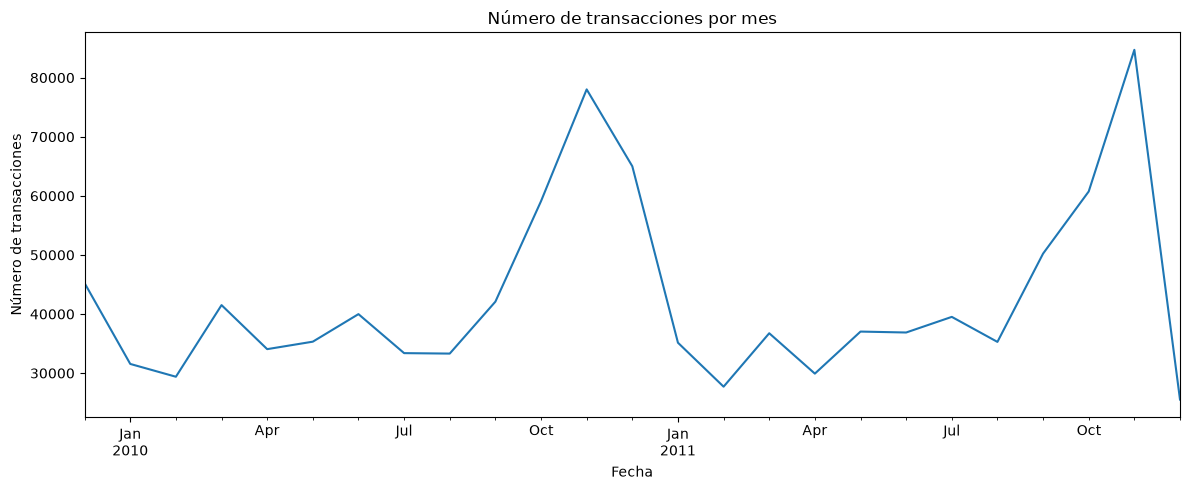

np.int64(84711)

In [72]:
# ¿Cuántas transacciones hubo en cada mes concreto del periodo?
transacciones_mes = df.set_index("InvoiceDate").resample("ME").size()
transacciones_mes.plot(figsize=(12, 5))

plt.title("Número de transacciones por mes")
plt.xlabel("Fecha")
plt.ylabel("Número de transacciones")
plt.tight_layout()
plt.show()

transacciones_mes.max()

La actividad aumenta claramente durante el segundo semestre, alcanzando su máximo en noviembre (84.711 transacciones).
Los meses de febrero y abril presentan los menores volúmenes.
Este patrón sugiere una fuerte estacionalidad, especialmente vinculada al periodo previo a Navidad.


### 3. Análisis de ventas y comportamiento de clientes

#### 3.1 Ventas
Analizamos el volumen y la evolución temporal de las ventas a partir de las transacciones válidas.

In [ ]:
# Estudiamos las ventas totales, excluyendo cancelaciones, cantidades no positivas y precios no positivos
ventas = df[
    (~df["Invoice"].astype(str).str.startswith("C")) &
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

ventas["TotalPrice"] = ventas["Quantity"] * ventas["Price"]

print(f"Ventas totales: £{ventas['TotalPrice'].sum():,.2f}")

Ventas totales: £20,972,594.57


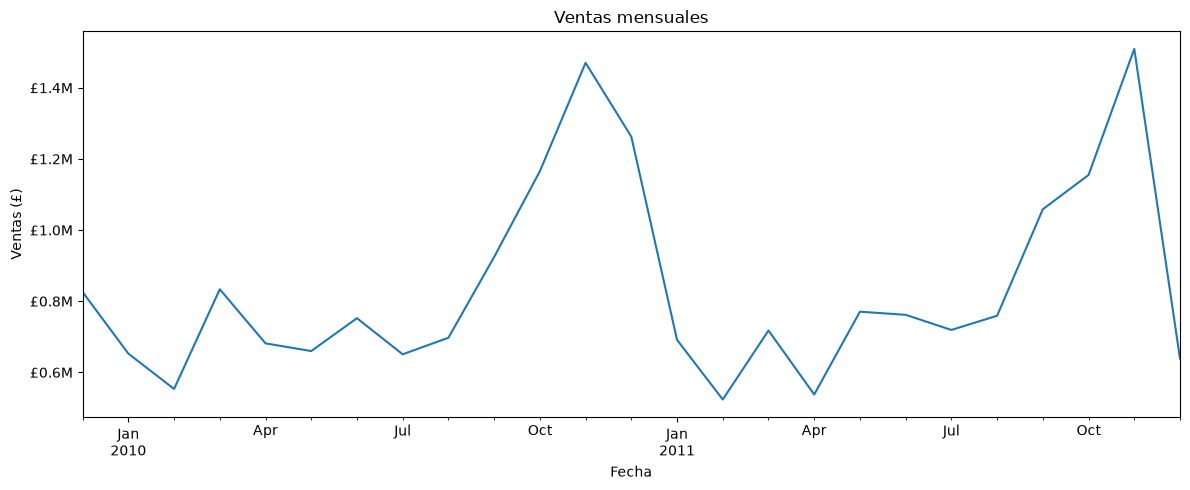

In [82]:
ventas_mensuales = (
    ventas.set_index("InvoiceDate")["TotalPrice"]
          .resample("ME")
          .sum()
)

import matplotlib.ticker as mtick

ventas_mensuales.plot(figsize=(12, 5))

plt.title("Ventas mensuales")
plt.xlabel("Fecha")
plt.ylabel("Ventas (£)")

plt.gca().yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f"£{x/1e6:.1f}M")
)

plt.tight_layout()
plt.show()

In [83]:
mes_max_ventas = ventas_mensuales.idxmax()
max_ventas = ventas_mensuales.max()

print(f"Mes con mayor volumen de ventas: {mes_max_ventas:%Y-%m}")
print(f"Importe: £{max_ventas:,.2f}")

Mes con mayor volumen de ventas: 2011-11
Importe: £1,509,496.33


#### 3.2 Cancelaciones
Analizamos el volumen y el impacto económico de las operaciones canceladas.

In [84]:
# Importe de las cancelaciones
cancelaciones = df[
    df["Invoice"].astype(str).str.startswith("C")
].copy()

cancelaciones["TotalPrice"] = (
    cancelaciones["Quantity"] * cancelaciones["Price"]
)

cancelaciones.shape

(19494, 9)

In [89]:
# Número de facturas de cancelación
print(f"Número de facturas de cancelación: {cancelaciones['Invoice'].nunique()}")

Número de facturas de cancelación: 8292


In [88]:
print(f"Importe TOTAL de cancelaciones: £{cancelaciones['TotalPrice'].sum():,.2f}")

Importe TOTAL de cancelaciones: £-1,526,667.86


Ahora podemos comparar ventas y cancelaciones:

In [90]:
ventas_totales = ventas["TotalPrice"].sum()
cancelaciones_totales = abs(cancelaciones["TotalPrice"].sum())

ratio_cancelaciones = (
    cancelaciones_totales / ventas_totales * 100
)

print(f"Ventas: £{ventas_totales:,.2f}")
print(f"Cancelaciones: £{cancelaciones_totales:,.2f}")
print(f"Cancelaciones sobre ventas: {ratio_cancelaciones:.2f}%")

Ventas: £20,972,594.57
Cancelaciones: £1,526,667.86
Cancelaciones sobre ventas: 7.28%


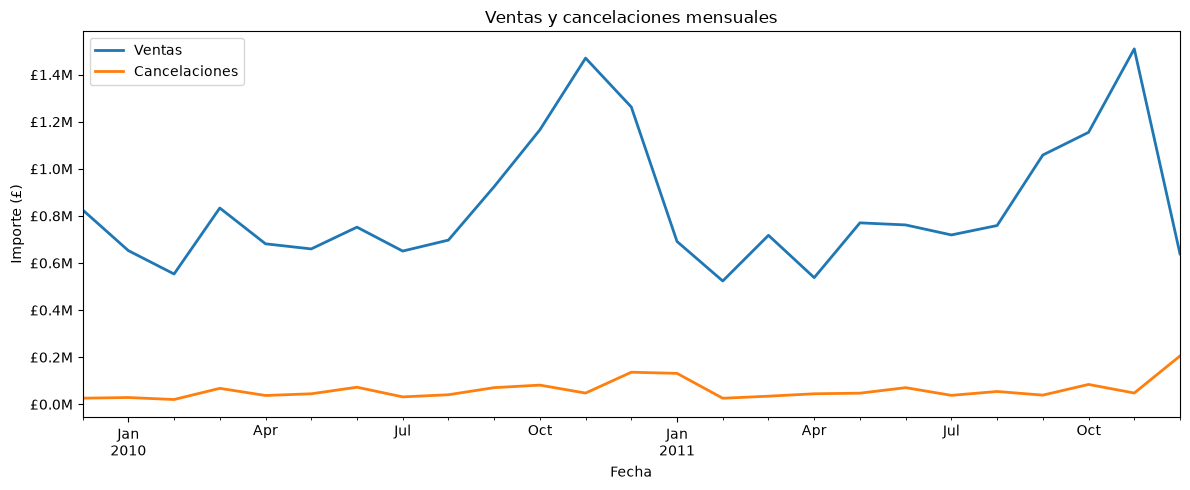

In [92]:
comparativa_mensual = pd.concat(
    [
        ventas_mensuales.rename("Ventas"),
        cancelaciones_mensuales.abs().rename("Cancelaciones")
    ],
    axis=1
)

comparativa_mensual.plot(
    figsize=(12, 5),
    linewidth=2
)

plt.title("Ventas y cancelaciones mensuales")
plt.xlabel("Fecha")
plt.ylabel("Importe (£)")

plt.gca().yaxis.set_major_formatter(
    mtick.FuncFormatter(lambda x, _: f"£{x/1e6:.1f}M")
)

plt.legend()
plt.tight_layout()
plt.show()

Se identifican 8.292 facturas con cancelaciones que representan £1,53 millones, equivalentes al 7,28% del volumen de ventas.
Las cancelaciones no siguen patrones similares a las ventas ni presentan periodos específicos de mayor incidencia.
Las cancelaciones tienen un volumen económico relevante, pero son minoritarias respecto a las ventas. Por tanto, para calcular gasto del cliente, no debemos mezclar cancelaciones con ventas
Su comportamiento a nivel individual podrá analizarse posteriormente como una posible variable de comportamiento.


#### 3.3 Construcción de variables de clientes y su comportamiento
Creacíon de nuevas variables agrupadas por clientes para poder estudiar su comportamiento

Analizamos el comportamiento de compra a nivel cliente para identificar diferencias en frecuencia, volumen y gasto.

Primero creamos el dataset de compras válidas, excluyendo cancelaciones, cantidades no positivas, precios no positivos y clientes no identificados:

In [93]:
clientes = df[
    (~df["Invoice"].astype(str).str.startswith("C")) &
    (df["Customer ID"].notna()) &
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

clientes["TotalPrice"] = clientes["Quantity"] * clientes["Price"]

clientes.shape

(805549, 9)

Ahora agregamos la información por cliente:

In [116]:
perfil_clientes = (
    clientes.groupby("Customer ID")
    .agg(
        facturas=("Invoice", "nunique"), # facturas diferentes tiene cada cliente
        productos_distintos=("StockCode", "nunique"), #productos distintos de cada cliente
        unidades=("Quantity", "sum"), #suma todas las unidades compradas por cada cliente
        gasto=("TotalPrice", "sum") #gasto total de cada cliente
    )
)

perfil_clientes.describe()

,facturas,productos_distintos,unidades,gasto
count,5878.000000,5878.000000,5878.000000,5878.000000
mean,6.289384,81.989112,1821.396223,3018.616737
std,13.009406,116.484552,8963.011855,14737.731040
min,1.000000,1.000000,1.000000,2.950000
25%,1.000000,19.000000,190.000000,348.762500
50%,3.000000,45.000000,491.500000,898.915000
75%,7.000000,103.000000,1376.000000,2307.090000
max,398.000000,2550.000000,367193.000000,608821.650000


La media es bastante superior a la mediana, tenemos distribuciones muy sesgadas, especialmente en unidades y gasto.
Por tanto, la media no representa demasiado bien al cliente típico. Lo visualizamos en un gráfico:

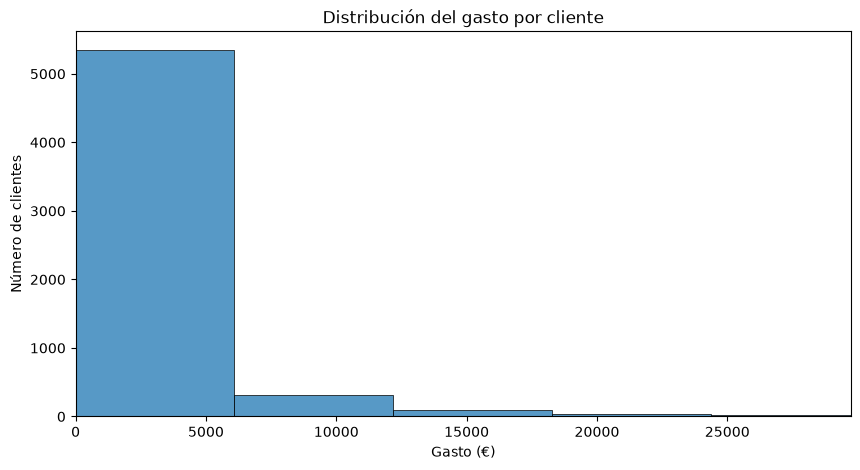

In [117]:
plt.figure(figsize=(10, 5))

sns.histplot(
    perfil_clientes["gasto"],
    bins=100
)

plt.xlim(0, perfil_clientes["gasto"].quantile(0.99))

plt.title("Distribución del gasto por cliente")
plt.xlabel("Gasto (€)")
plt.ylabel("Número de clientes")

plt.show()

Añadimos ticket medio:

In [118]:
perfil_clientes["ticket_medio"] = (
    perfil_clientes["gasto"] / perfil_clientes["facturas"]
)

perfil_clientes["ticket_medio"].describe()

count     5878.000000
mean       391.726538
std       1215.071054
min          2.950000
25%        181.652500
50%        285.070500
75%        420.570000
max      84236.250000
Name: ticket_medio, dtype: float64

Añadimos la recencia de cada cliente, que será fundamental para RFM:

In [119]:
# Calculamos la fecha máxima de compra en el dataset
fecha_maxima = clientes["InvoiceDate"].max()

#Obtenemos la última compra de cada cliente
ultima_compra = (
    clientes.groupby("Customer ID")["InvoiceDate"]
    .max()
)

# Calculamos los dias desde esa compra
perfil_clientes["recencia"] = (
    fecha_maxima - ultima_compra
).dt.days

perfil_clientes["recencia"].describe()

count    5878.000000
mean      200.331916
std       209.338707
min         0.000000
25%        25.000000
50%        95.000000
75%       379.000000
max       738.000000
Name: recencia, dtype: float64

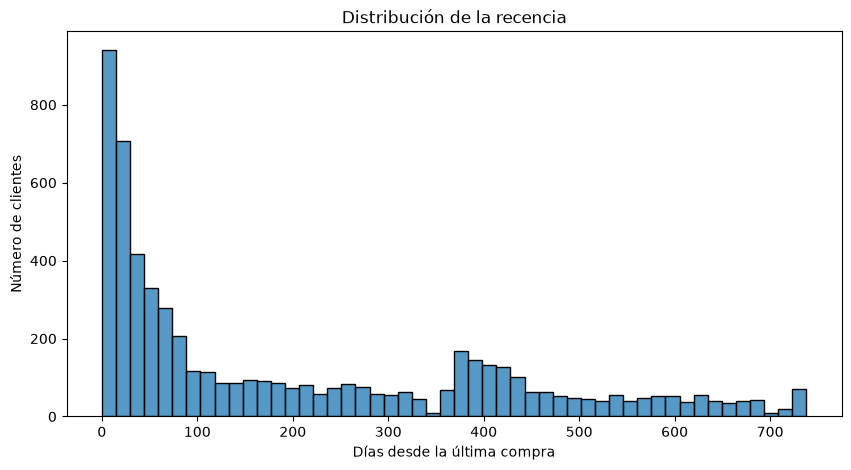

In [120]:
plt.figure(figsize=(10, 5))

sns.histplot(
    perfil_clientes["recencia"],
    bins=50
)

plt.title("Distribución de la recencia")
plt.xlabel("Días desde la última compra")
plt.ylabel("Número de clientes")

plt.show()

Añadimos antigédad de cliente: 

In [121]:
primera_compra = (
    clientes.groupby("Customer ID")["InvoiceDate"]
    .min()
)

perfil_clientes["antiguedad_dias"] = (
    ultima_compra - primera_compra
).dt.days

perfil_clientes["antiguedad_dias"].describe()

count    5878.000000
mean      273.022457
std       258.807591
min         0.000000
25%         0.000000
50%       220.500000
75%       511.000000
max       738.000000
Name: antiguedad_dias, dtype: float64

Ahora miramos las correlaciones:

In [122]:
perfil_clientes.corr(numeric_only=True)

,facturas,productos_distintos,unidades,gasto,ticket_medio,recencia,antiguedad_dias
facturas,1.000000,0.693113,0.577018,0.629570,0.035110,-0.257013,0.441936
productos_distintos,0.693113,1.000000,0.391361,0.407043,0.051937,-0.325477,0.499124
unidades,0.577018,0.391361,1.000000,0.873558,0.257786,-0.111201,0.203253
gasto,0.629570,0.407043,0.873558,1.000000,0.267103,-0.125080,0.213360
ticket_medio,0.035110,0.051937,0.257786,0.267103,1.000000,-0.027813,0.016586
recencia,-0.257013,-0.325477,-0.111201,-0.125080,-0.027813,1.000000,-0.563569
antiguedad_dias,0.441936,0.499124,0.203253,0.213360,0.016586,-0.563569,1.000000


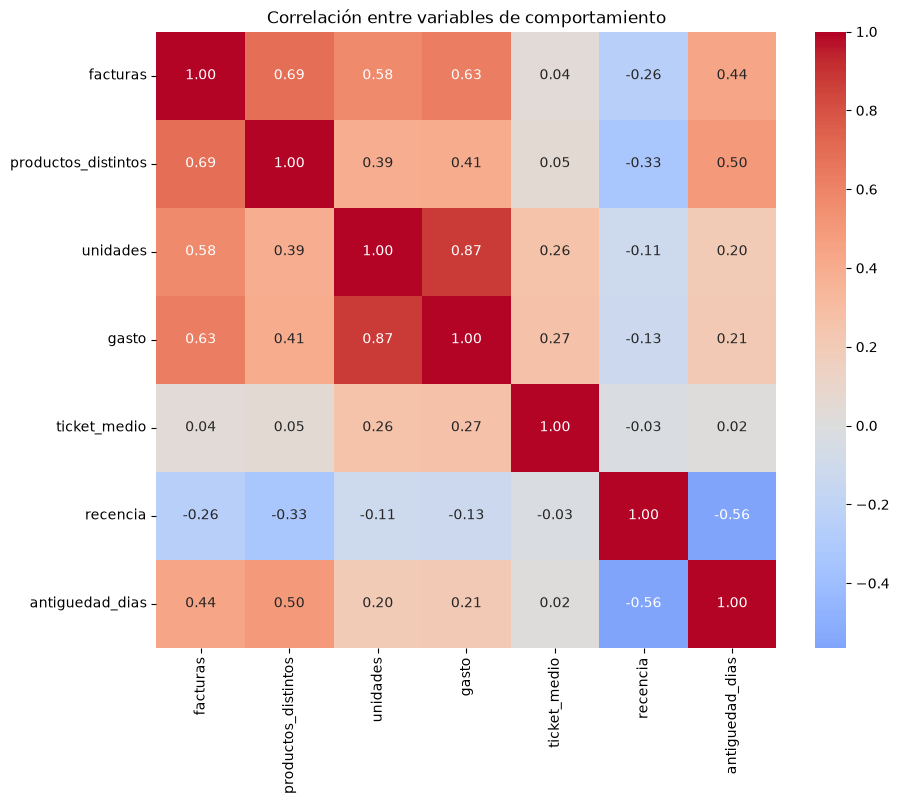

In [123]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    perfil_clientes.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlación entre variables de comportamiento")
plt.show()

**Conclusiones del comportamiento de clientes**

El análisis de los 5.878 clientes muestra una elevada heterogeneidad en sus patrones de compra.

* El **gasto está muy concentrado**: más de 5.000 clientes gastan menos de aproximadamente 5.500 €, mientras que menos de 1.000 clientes superan ese nivel. La mediana es de 898,92 €, frente a una media de 3.018,62 €, lo que confirma una distribución fuertemente sesgada hacia valores altos.

* La **frecuencia de compra también presenta una gran dispersión**. La mediana es de 3 facturas por cliente, mientras que la media es de 6,29 y el máximo alcanza 398 facturas. Esto indica que existe un grupo reducido de clientes con una actividad de compra muy superior al cliente típico.

* El **volumen de unidades compradas** muestra una concentración todavía mayor. La mediana es de 491,5 unidades, frente a una media de 1.821,4, con un máximo de 367.193 unidades.

* El **ticket medio** presenta también una distribución muy asimétrica. La mediana es de 285,07 €, mientras que la media alcanza 391,73 € y existe un máximo de 84.236,25 €. Por tanto, unos pocos clientes con tickets excepcionalmente elevados elevan considerablemente la media.

* La **recencia** presenta una mediana de 95 días y una media de 200,33 días. El 25% de los clientes realizó su última compra hace 25 días o menos, mientras que el 25% más inactivo presenta una recencia superior a 379 días. Esto muestra diferencias importantes en el nivel de actividad reciente.

* La **antigüedad** también es heterogénea. La mediana es de 220,5 días y el 25% de los clientes presenta una antigüedad de 0 días, lo que indica que una parte importante de los clientes realizó sus compras dentro de un periodo muy corto.

* Las correlaciones muestran una relación fuerte entre **unidades y gasto (r = 0,87)**. También existe una relación positiva entre facturas y gasto (r = 0,63), y entre facturas y productos distintos (r = 0,69). Esto indica que los clientes que compran con mayor frecuencia tienden a generar más volumen y gasto, aunque estas variables no son equivalentes.

* El **ticket medio presenta una correlación muy baja con la frecuencia de compra (r = 0,04)**. Esto sugiere que comprar muchas veces no implica necesariamente realizar tickets de mayor importe.

* La **recencia presenta correlaciones negativas con la frecuencia (-0,26), los productos distintos (-0,33) y el gasto (-0,13)**. Los clientes con mayor actividad histórica tienden, en promedio, a presentar una menor recencia, aunque la relación no es suficientemente fuerte como para explicar por sí sola el comportamiento del cliente.

En conjunto, los resultados muestran que los clientes presentan perfiles muy diferentes en términos de **frecuencia, volumen, valor económico y actividad reciente**. Por ello, estas dimensiones se utilizarán en la siguiente etapa para construir una segmentación de clientes basada en RFM y posteriormente analizar cómo estas características pueden relacionarse con el churn.
